# he_cluster_movies.py

*Generated from `he_cluster_movies.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
he_cluster_movies.py - He clusters in the CIM dumps: statistics, tracks and renders.

Reads dump.full-<cycle>.lammps, keeps only He, finds He clusters in every frame
(two He in one cluster when closer than CUTOFF_A = 2.5 A, periodic in x, y;
same rule as ovito_insertion_movies.py), follows them between frames by shared
atom IDs, and renders the He alone.  The host (W, C) only locates the surface
(Gibbs dividing surface), so each He has a depth.  The He type is detected
(WC decks: 3, W decks: 2; or --he-type).

    python he_cluster_movies.py [--dir RUN] [--area 3567] [--stride 5] [--jobs 4]
        --gif-frames N   --hide-isolated   --no-gif (CSVs + figures only)
        --color-by size|depth|track        --draw atoms|centroids

Outputs (default <dir>/he_clusters/):
    he_clusters_per_cycle.csv   per frame: He, isolated He, clusters per size bin
                                (2-3 / 4-6 / 7+), largest, mean depth, surface
    he_cluster_list.csv         per cluster per frame: track, size, centroid,
                                depth, radius of gyration
    he_cluster_tracks.csv       per tracked cluster: first/last cycle, sizes,
                                depth, merged_into
    he_cluster_evolution.png    he_depth_profile.png    he_clusters_final.png
    he_clusters.gif             iso + side view + counts with a moving cursor

Requires numpy, scipy, matplotlib, pillow (pandas reads faster).
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'he_cluster_movies.py'
NB_RUN = "."          # run folder with dump.full-*.lammps
ARGS = ["--dir", NB_RUN, "--jobs", "4"]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

The cells below are the script.  They need the run's dumps (and OVITO where it is imported), so they were not run when this notebook was built; the outputs further down come from a cluster run.

In [ ]:
import argparse
import csv
import glob
import io
import os
import re
import sys
from concurrent.futures import ProcessPoolExecutor

import numpy as np

try:
    import pandas as pd
except ImportError:          # plain numpy reader is used instead
    pd = None

import matplotlib
if "--show" not in sys.argv:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

In [ ]:
# ===========================================================================
# SETTINGS (all also on the command line, see --help)
# ===========================================================================
INPUT_DIR = "."
DUMP_PATTERN = "dump.full-*.lammps"   # one frame per file, cycle in the name
OUT_DIR = None                        # None = <INPUT_DIR>/he_clusters
HE_TYPE = None                        # None = auto (3 if any type-3 atoms, else 2)

CUTOFF_A = 2.5                        # He-He distance that joins a cluster (A)
SIZE_BINS = [(2, 3), (4, 6), (7, None)]   # (min, max) He per cluster; None = no max
TRACK_MIN_SIZE = 2                    # clusters this size or larger get a track id

T_CYCLE_PS = 20.0                     # insertion-to-insertion time (ps)
IMPACT_AREA_A2 = None                 # e.g. 3567 (WC basal), 3420 (prism), 3490 (W)
                                      # None = guessed from the folder name, or no fluence

# --- surface (Gibbs dividing surface of the host atoms) ---------------------
SURFACE = "gibbs"                     # "gibbs" or "none" (depth then = top of box - z)
BULK_WINDOW = (0.30, 0.60)            # part of the slab thickness used as "bulk"

In [ ]:
# --- rendering --------------------------------------------------------------
GIF_FRAMES = 150                      # frames in the GIF (evenly spaced)
GIF_FPS = 10
FIG_SIZE = (13.0, 7.0)                # inches
FIG_DPI = 100                         # GIF frames;  still images use 2x this
VIEW_ELEV, VIEW_AZIM = 22, -58        # 3D camera
DEPTH_WINDOW_A = None                 # None = auto (deepest He + 5 A), same for every frame
ABOVE_SURFACE_A = 6.0                 # room drawn above the surface

COLOR_BY = "size"                     # "size", "depth" or "track"
DRAW = "atoms"                        # "atoms" (every He) or "centroids" (one per cluster)
HIDE_ISOLATED = False
# He colours: yellow for lone He, darkening to red for big clusters
ISOLATED_COLOR = "#ffe680"
BIN_COLORS = ["#f5c000", "#ff8c00", "#c1121f"]
ATOM_SIZE = 26                        # matplotlib marker area for one He (pt^2)
ISOLATED_ALPHA = 0.55
SURFACE_COLOR = "#7f7f7f"
TEXT_COLOR = "#222222"

# ===========================================================================

In [ ]:
# ---------------------------------------------------------------------------
# reading dumps
# ---------------------------------------------------------------------------
def cycle_of(path):
    """Cycle number from 'dump.full-123.lammps' (last integer in the name)."""
    nums = re.findall(r"(\d+)", os.path.basename(path))
    return int(nums[-1]) if nums else -1


def read_frame(path):
    """One LAMMPS text dump frame -> dict(box, ids, types, pos, timestep).

        Handles x, xs, xu and xsu style columns; reads the first frame only.

    """
    with open(path, "r") as fh:
        lines = []
        for _ in range(9):
            lines.append(fh.readline())
        if not lines[0].startswith("ITEM: TIMESTEP"):
            raise ValueError("%s is not a LAMMPS text dump" % path)
        step = int(lines[1].split()[0])
        natoms = int(lines[3].split()[0])
        bounds = np.array([[float(v) for v in lines[i].split()[:2]] for i in (5, 6, 7)])
        if "xy" in lines[4]:
            print("  NOTE: triclinic box in %s - tilt ignored" % os.path.basename(path))
        cols = lines[8].split()[2:]
        if pd is not None:
            df = pd.read_csv(fh, sep=r"\s+", header=None, names=cols, nrows=natoms,
                             engine="c")
            data = {c: df[c].to_numpy() for c in cols}
        else:
            arr = np.loadtxt(fh, max_rows=natoms, ndmin=2)
            data = {c: arr[:, i] for i, c in enumerate(cols)}
    lo, hi = bounds[:, 0], bounds[:, 1]
    L = hi - lo
    pos = np.empty((natoms, 3))
    for k, ax in enumerate("xyz"):
        for name, scaled in ((ax, False), (ax + "u", False), (ax + "s", True), (ax + "su", True)):
            if name in data:
                v = np.asarray(data[name], float)
                pos[:, k] = lo[k] + v * L[k] if scaled else v
                break
        else:
            raise ValueError("no %s coordinate column in %s" % (ax, path))
    ids = np.asarray(data["id"], np.int64) if "id" in data else np.arange(1, natoms + 1)
    types = np.asarray(data["type"], np.int64)
    return dict(step=step, lo=lo, hi=hi, L=L, ids=ids, types=types, pos=pos)

In [ ]:
# ---------------------------------------------------------------------------
# analysis of one frame
# ---------------------------------------------------------------------------
def gibbs_surface(z_host, L, lo):
    """Gibbs dividing surface of the host: z_mid + N(above z_mid) / (rho_bulk * A),
        with rho_bulk from BULK_WINDOW of the slab.
    """
    if z_host.size < 10:
        return np.nan
    zmin, zmax = np.percentile(z_host, [0.5, 99.9])
    t = zmax - zmin
    za, zb = zmin + BULK_WINDOW[0] * t, zmin + BULK_WINDOW[1] * t
    area = L[0] * L[1]
    rho = np.count_nonzero((z_host >= za) & (z_host < zb)) / (area * (zb - za))
    if rho <= 0:
        return np.nan
    return zb + np.count_nonzero(z_host >= zb) / (rho * area)


def find_clusters(pos, L, lo, cutoff):
    """Connected components of He within `cutoff`, periodic in x and y only.

    Returns labels (0..n-1, sorted so cluster 0 is the largest) and sizes.
    """
    n = len(pos)
    if n == 0:
        return np.zeros(0, int), np.zeros(0, int)
    p = pos - lo
    p[:, :2] %= L[:2]
    zspan = max(p[:, 2].max() - p[:, 2].min(), 1.0) + 4 * cutoff
    p[:, 2] -= p[:, 2].min()                      # z is not periodic: pad the box
    box = np.array([L[0], L[1], zspan + 4 * cutoff])
    tree = cKDTree(p, boxsize=box)
    pairs = tree.query_pairs(cutoff, output_type="ndarray")
    g = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(n, n)) \
        if len(pairs) else coo_matrix((n, n))
    nc, lab = connected_components(g, directed=False)
    sizes = np.bincount(lab, minlength=nc)
    order = np.argsort(-sizes, kind="stable")      # largest first
    remap = np.empty(nc, int)
    remap[order] = np.arange(nc)
    return remap[lab], sizes[order]


def unwrap_cluster(p, L):
    """Bring the atoms of one cluster next to each other across x/y PBC."""
    q = p.copy()
    ref = q[0, :2]
    d = q[:, :2] - ref
    q[:, :2] = ref + d - L[:2] * np.round(d / L[:2])
    return q


def analyse_file(args):
    """Worker: read one dump and return the He-only frame record."""
    path, he_type, cutoff, surface = args
    f = read_frame(path)
    he = f["types"] == he_type
    host = ~he
    z_surf = gibbs_surface(f["pos"][host, 2], f["L"], f["lo"]) if surface == "gibbs" \
        else float(f["pos"][host, 2].max()) if host.any() else np.nan
    pos = f["pos"][he]
    ids = f["ids"][he]
    lab, sizes = find_clusters(pos, f["L"], f["lo"], cutoff)
    # unwrapped positions and centroids per cluster
    upos = pos.copy()
    cents = np.zeros((len(sizes), 3))
    rg = np.zeros(len(sizes))
    for c in range(len(sizes)):
        m = lab == c
        if sizes[c] > 1:
            q = unwrap_cluster(pos[m], f["L"])
            cen = q.mean(axis=0)
            shift = np.floor((cen[:2] - f["lo"][:2]) / f["L"][:2]) * f["L"][:2]
            q[:, :2] -= shift                        # centroid back inside the box
            cen[:2] -= shift
            upos[m] = q
            rg[c] = np.sqrt(((q - cen) ** 2).sum(axis=1).mean())
            cents[c] = cen
        else:
            cents[c] = pos[m][0]
    return dict(cycle=cycle_of(path), step=f["step"], lo=f["lo"], L=f["L"],
                z_surf=z_surf, ids=ids, pos=upos, lab=lab, sizes=sizes,
                cents=cents, rg=rg)


def detect_he_type(paths):
    """3 if the newest dump has type-3 atoms (WC deck), else 2 (W deck)."""
    f = read_frame(paths[-1])
    types = set(np.unique(f["types"]).tolist())
    he = 3 if 3 in types else 2
    print("  He type detected: %d  (types in %s: %s)" % (
        he, os.path.basename(paths[-1]), sorted(types)))
    return he

In [ ]:
# ---------------------------------------------------------------------------
# tracking clusters from frame to frame (by shared He atom IDs)
# ---------------------------------------------------------------------------
def track_clusters(frames, min_size):
    """Track id for every cluster of >= min_size He.  A cluster continues the
        previous one it shares most He IDs with; on a merge the larger share keeps
        the id and the other track ends (merged_into recorded).
    """
    next_id = 0
    prev = None                                   # (ids, lab, track_of_label)
    tracks = {}
    for fr in frames:
        sizes = fr["sizes"]
        tr = np.full(len(sizes), -1, int)
        big = np.where(sizes >= min_size)[0]
        if prev is not None and len(big):
            pid, plab, ptr = prev
            lookup = dict(zip(pid.tolist(), plab.tolist()))
            cand = []                             # (overlap, current, prev_track)
            for c in big:
                memb = fr["ids"][fr["lab"] == c]
                pl = [lookup.get(i, -1) for i in memb.tolist()]
                pl = [ptr[x] for x in pl if x >= 0 and ptr[x] >= 0]
                if pl:
                    u, cnt = np.unique(pl, return_counts=True)
                    for t, k in zip(u, cnt):
                        cand.append((int(k), int(c), int(t)))
            cand.sort(reverse=True)
            used_c, used_t = set(), set()
            for k, c, t in cand:
                if c in used_c or t in used_t:
                    continue
                tr[c] = t
                used_c.add(c)
                used_t.add(t)
            # tracks that lost their atoms to another cluster = merged
            for k, c, t in cand:
                if t not in used_t and t in tracks and tracks[t]["merged_into"] is None:
                    tracks[t]["merged_into"] = int(tr[c]) if tr[c] >= 0 else None
        for c in big:
            if tr[c] < 0:
                tr[c] = next_id
                next_id += 1
            t = int(tr[c])
            rec = tracks.setdefault(t, dict(track=t, first_cycle=fr["cycle"], max_size=0,
                                            merged_into=None, history=[]))
            rec["last_cycle"] = fr["cycle"]
            rec["max_size"] = max(rec["max_size"], int(sizes[c]))
            rec["last_size"] = int(sizes[c])
            rec["last_depth"] = float(fr["z_surf"] - fr["cents"][c, 2])
            if "first_depth" not in rec:
                rec["first_depth"] = rec["last_depth"]
            rec["history"].append((fr["cycle"], int(sizes[c])))
        fr["track"] = tr
        prev = (fr["ids"], fr["lab"], tr)
    return tracks

In [ ]:
# ---------------------------------------------------------------------------
# bookkeeping
# ---------------------------------------------------------------------------
def bin_label(lo, hi):
    return "%d+" % lo if hi is None else ("%d" % lo if lo == hi else "%d-%d" % (lo, hi))


def bin_of(size):
    for k, (lo, hi) in enumerate(SIZE_BINS):
        if size >= lo and (hi is None or size <= hi):
            return k
    return -1


def bin_counts(sizes):
    return [int(np.sum((sizes >= lo) & (sizes <= (hi if hi is not None else 10 ** 9))))
            for lo, hi in SIZE_BINS]


def fluence(cycle):
    return None if not IMPACT_AREA_A2 else cycle / (IMPACT_AREA_A2 * 1e-20)


def stamp(cycle):
    """'Cycle #, Time # ns, Fluence # x10^19 He m^-2' (same style as the renders)."""
    s = "Cycle %d, Time %.2f ns" % (cycle, cycle * T_CYCLE_PS / 1000.0)
    f = fluence(cycle)
    if f is not None:
        s += ", Fluence %.2f$\\times10^{19}$ He m$^{-2}$" % (f / 1e19)
    return s


def write_tables(frames, tracks, out):
    p = os.path.join(out, "he_clusters_per_cycle.csv")
    with open(p, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["cycle", "time_ns", "fluence_m2", "he_count", "he_isolated",
                    "he_in_clusters"] + ["clusters_%s" % bin_label(*b).replace("+", "plus")
                                          for b in SIZE_BINS]
                   + ["largest_cluster", "mean_he_depth_A", "z_surf_A"])
        for fr in frames:
            s = fr["sizes"]
            iso = int(np.sum(s == 1))
            n = int(s.sum())
            mean_depth = float(np.mean(fr["z_surf"] - fr["pos"][:, 2])) if n else float("nan")
            f = fluence(fr["cycle"])
            w.writerow([fr["cycle"], round(fr["cycle"] * T_CYCLE_PS / 1000, 3),
                        "" if f is None else "%.4e" % f, n, iso, n - iso]
                       + bin_counts(s) + [int(s.max()) if n else 0,
                                          round(mean_depth, 3),
                                          round(float(fr["z_surf"]), 3)])
    print("  wrote", p)
    p = os.path.join(out, "he_cluster_list.csv")
    with open(p, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["cycle", "cluster", "track", "size", "x_A", "y_A", "z_A",
                    "depth_A", "radius_gyration_A"])
        for fr in frames:
            for c, sz in enumerate(fr["sizes"]):
                if sz < 2:
                    continue
                x, y, z = fr["cents"][c]
                w.writerow([fr["cycle"], c, int(fr["track"][c]), int(sz), round(x, 3),
                            round(y, 3), round(z, 3), round(fr["z_surf"] - z, 3),
                            round(fr["rg"][c], 3)])
    print("  wrote", p)
    p = os.path.join(out, "he_cluster_tracks.csv")
    with open(p, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["track", "first_cycle", "last_cycle", "max_size", "last_size",
                    "first_depth_A", "last_depth_A", "merged_into"])
        for t in sorted(tracks.values(), key=lambda r: -r["max_size"]):
            w.writerow([t["track"], t["first_cycle"], t["last_cycle"], t["max_size"],
                        t["last_size"], round(t["first_depth"], 2), round(t["last_depth"], 2),
                        "" if t["merged_into"] is None else t["merged_into"]])
    print("  wrote", p)

In [ ]:
# ---------------------------------------------------------------------------
# plots
# ---------------------------------------------------------------------------
def xvals(cycles):
    f = fluence(np.asarray(cycles, float))
    if f is None:
        return np.asarray(cycles, float), "Impact cycle"
    return f / 1e19, r"Fluence ($10^{19}$ He m$^{-2}$)"


def evolution_figure(frames, tracks, out, title):
    cyc = np.array([fr["cycle"] for fr in frames])
    x, xl = xvals(cyc)
    counts = np.array([bin_counts(fr["sizes"]) for fr in frames])
    largest = np.array([fr["sizes"].max() if len(fr["sizes"]) else 0 for fr in frames])
    nhe = np.array([fr["sizes"].sum() for fr in frames])
    iso = np.array([np.sum(fr["sizes"] == 1) for fr in frames])
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
    ax = axs[0]
    for k, (lo, hi) in enumerate(SIZE_BINS):
        ax.plot(x, counts[:, k], color=BIN_COLORS[k], lw=1.6, label="%s He" % bin_label(lo, hi))
    ax.set_ylabel("Clusters")
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.set_title("He clusters by size")
    ax.legend(frameon=False)
    ax = axs[1]
    ax.plot(x, nhe, color="#444444", lw=1.6, label="He retained")
    ax.plot(x, nhe - iso, color=BIN_COLORS[1], lw=1.6, label="He in clusters (2+)")
    ax.plot(x, iso, color="#c9a400", lw=1.2, ls="--", label="isolated He")
    ax2 = ax.twinx()
    ax2.plot(x, largest, color=BIN_COLORS[2], lw=1.2, alpha=0.8)
    ax2.set_ylabel("Largest cluster (He)", color=BIN_COLORS[2])
    ax2.tick_params(axis="y", colors=BIN_COLORS[2])
    ax.set_ylabel("He atoms")
    ax.set_title("Retained He and largest cluster")
    ax.legend(frameon=False, loc="upper left")
    ax = axs[2]
    top = sorted(tracks.values(), key=lambda r: -r["max_size"])[:8]
    cmap = plt.get_cmap("viridis")
    for i, t in enumerate(top):
        h = np.array(t["history"])
        xx, _ = xvals(h[:, 0])
        ax.step(xx, h[:, 1], where="post", color=cmap(i / max(len(top) - 1, 1)), lw=1.5,
                label="#%d (ends %s)" % (t["track"], "merged" if t["merged_into"] is not None
                                           else "%d He" % t["last_size"]))
    ax.set_ylabel("He in cluster")
    ax.set_title("Growth of the %d biggest tracked clusters" % len(top))
    if top:
        ax.legend(frameon=False, fontsize=8, ncol=2)
    for ax in axs:
        ax.set_xlabel(xl)
        ax.grid(True, color="#dddddd", lw=0.6)
        ax.set_axisbelow(True)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    p = os.path.join(out, "he_cluster_evolution.png")
    fig.savefig(p, dpi=2 * FIG_DPI)
    plt.close(fig)
    print("  wrote", p)


def depth_profile_figure(frames, out, title, nshow=4, binw=2.0):
    idx = np.unique(np.linspace(0, len(frames) - 1, nshow).round().astype(int))
    dmax = max(float(np.nanmax(fr["z_surf"] - fr["pos"][:, 2])) if len(fr["pos"]) else 0
               for fr in frames)
    edges = np.arange(-ABOVE_SURFACE_A, dmax + binw, binw)
    mids = 0.5 * (edges[1:] + edges[:-1])
    fig, axs = plt.subplots(1, 2, figsize=(10, 5.6), sharey=True)
    shades = plt.get_cmap("plasma")(np.linspace(0.15, 0.8, len(idx)))
    for col, i in zip(shades, idx):
        fr = frames[i]
        if not len(fr["pos"]):
            continue
        d = fr["z_surf"] - fr["pos"][:, 2]
        size_of_atom = fr["sizes"][fr["lab"]]
        for ax, m in ((axs[0], size_of_atom == 1), (axs[1], size_of_atom > 1)):
            h, _ = np.histogram(d[m], edges)
            ax.plot(h, mids, color=col, lw=1.6, label="cycle %d" % fr["cycle"])
    axs[0].set_title("Isolated He")
    axs[1].set_title("He in clusters (2+)")
    for ax in axs:
        ax.axhline(0, color=SURFACE_COLOR, lw=1, ls="--")
        ax.set_xlabel("He atoms per %.0f Å bin" % binw)
        ax.grid(True, color="#dddddd", lw=0.6)
    axs[0].set_ylabel("Depth below the surface (Å)")
    axs[0].invert_yaxis()
    axs[1].legend(frameon=False)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    p = os.path.join(out, "he_depth_profile.png")
    fig.savefig(p, dpi=2 * FIG_DPI)
    plt.close(fig)
    print("  wrote", p)

In [ ]:
# ---------------------------------------------------------------------------
# rendering
# ---------------------------------------------------------------------------
def atom_colors(fr, depth_lim, track_colors):
    """Colour and size of every He atom (or every cluster, for centroids)."""
    sizes = fr["sizes"]
    if DRAW == "centroids":
        n_per = sizes
        pos = fr["cents"]
        lab = np.arange(len(sizes))
    else:
        n_per = sizes[fr["lab"]]
        pos = fr["pos"]
        lab = fr["lab"]
    keep = n_per >= (2 if HIDE_ISOLATED else 1)
    if COLOR_BY == "depth":
        d = np.clip((fr["z_surf"] - pos[:, 2]) / max(depth_lim, 1e-9), 0, 1)
        col = plt.get_cmap("plasma_r")(0.1 + 0.85 * d)
    elif COLOR_BY == "track":
        tr = fr["track"][lab]
        col = np.array([track_colors(t % 20) if t >= 0 else matplotlib.colors.to_rgba(ISOLATED_COLOR)
                        for t in tr]).reshape(-1, 4)
    else:
        col = np.array([matplotlib.colors.to_rgba(ISOLATED_COLOR if s == 1 else BIN_COLORS[bin_of(s)])
                        for s in n_per]).reshape(-1, 4)
    col = col.copy()
    col[n_per == 1, 3] = ISOLATED_ALPHA
    if DRAW == "centroids":
        area = ATOM_SIZE * np.cbrt(n_per) ** 2 * 1.6
    else:
        area = np.where(n_per == 1, ATOM_SIZE * 0.7, ATOM_SIZE)
    return pos[keep], col[keep], np.asarray(area)[keep]


def render_frame(fr, geom, curves, title, dpi, track_colors):
    """One figure: 3D iso view (left), side view (top right), counts (bottom right)."""
    lo, L = fr["lo"], fr["L"]
    zs = fr["z_surf"]
    z_lo, z_hi = zs - geom["depth"], zs + ABOVE_SURFACE_A
    fig = plt.figure(figsize=FIG_SIZE)
    gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.0], height_ratios=[1.0, 0.75],
                          left=0.02, right=0.97, top=0.86, bottom=0.08, wspace=0.12, hspace=0.32)
    ax3 = fig.add_subplot(gs[:, 0], projection="3d")
    axs = fig.add_subplot(gs[0, 1])
    axc = fig.add_subplot(gs[1, 1])

    pos, col, area = atom_colors(fr, geom["depth"], track_colors)
    m = (pos[:, 2] >= z_lo) & (pos[:, 2] <= z_hi)
    # ---- 3D view
    ax3.scatter(pos[m, 0], pos[m, 1], pos[m, 2], s=area[m], c=col[m], depthshade=True,
                edgecolors="#00000040", linewidths=0.3)
    xx, yy = np.meshgrid([lo[0], lo[0] + L[0]], [lo[1], lo[1] + L[1]])
    ax3.plot_surface(xx, yy, np.full_like(xx, zs), color=SURFACE_COLOR, alpha=0.12,
                     shade=False)
    for x0, y0 in ((lo[0], lo[1]), (lo[0] + L[0], lo[1]), (lo[0] + L[0], lo[1] + L[1]),
                   (lo[0], lo[1] + L[1])):
        ax3.plot([x0, x0], [y0, y0], [z_lo, z_hi], color="#bbbbbb", lw=0.6)
    for z0 in (z_lo, zs):
        ax3.plot([lo[0], lo[0] + L[0], lo[0] + L[0], lo[0], lo[0]],
                 [lo[1], lo[1], lo[1] + L[1], lo[1] + L[1], lo[1]], [z0] * 5,
                 color="#999999" if z0 == zs else "#cccccc", lw=0.8 if z0 == zs else 0.6)
    ax3.set_xlim(lo[0], lo[0] + L[0])
    ax3.set_ylim(lo[1], lo[1] + L[1])
    ax3.set_zlim(z_lo, z_hi)
    try:
        ax3.set_box_aspect((L[0], L[1], z_hi - z_lo), zoom=0.95)
    except TypeError:                             # matplotlib < 3.6
        ax3.set_box_aspect((L[0], L[1], z_hi - z_lo))
    ax3.view_init(elev=VIEW_ELEV, azim=VIEW_AZIM)
    ax3.set_axis_off()
    # ---- side view (x - depth)
    d = zs - pos[:, 2]
    axs.scatter(pos[m, 0], d[m], s=area[m] * 0.8, c=col[m], edgecolors="#00000030",
                linewidths=0.3)
    axs.axhline(0, color=SURFACE_COLOR, lw=1.0, ls="--")
    axs.text(lo[0] + L[0] * 0.995, -0.4, "surface", va="bottom", ha="right", fontsize=9,
             color=SURFACE_COLOR)
    axs.set_xlim(lo[0], lo[0] + L[0])
    axs.set_ylim(geom["depth"], -ABOVE_SURFACE_A)
    axs.set_xlabel("x (Å)")
    axs.set_ylabel("Depth below surface (Å)")
    axs.set_title("Side view (all y)", fontsize=11)
    axs.grid(True, color="#eeeeee", lw=0.6)
    # ---- counts with a cursor
    cx, xl = curves["x"], curves["xlabel"]
    for k, (lo_, hi_) in enumerate(SIZE_BINS):
        axc.plot(cx, curves["counts"][:, k], color=BIN_COLORS[k], lw=1.5,
                 label="%s He" % bin_label(lo_, hi_))
    xnow = xvals([fr["cycle"]])[0][0]
    axc.axvline(xnow, color="#444444", lw=1.0)
    axc.set_xlim(cx.min(), cx.max())
    axc.set_ylim(0, max(1, curves["counts"].max()) * 1.1)
    axc.set_xlabel(xl)
    axc.set_ylabel("Clusters")
    axc.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    axc.legend(frameon=False, fontsize=9, loc="upper left")
    axc.grid(True, color="#eeeeee", lw=0.6)
    # ---- text block (top left)
    s = fr["sizes"]
    n = int(s.sum())
    b = bin_counts(s)
    lines = [(stamp(fr["cycle"]), TEXT_COLOR, "bold"),
             ("He retained: %d / %d  (%.0f%%)" % (n, max(fr["cycle"], 1),
                                                   100.0 * n / max(fr["cycle"], 1)),
              "#6a3d9a", "bold"),
             ("He clusters  " + " · ".join("%s: %d" % (bin_label(*bb), c)
                                           for bb, c in zip(SIZE_BINS, b))
              + "   (largest %d He)" % (int(s.max()) if n else 0), "#6a3d9a", "bold")]
    for i, (t, c, w) in enumerate(lines):
        fig.text(0.02, 0.965 - i * 0.035, t, fontsize=12, color=c, weight=w, va="top")
    handles = [Line2D([], [], marker="o", ls="", color=ISOLATED_COLOR, mec="#00000040",
                      ms=6, label="isolated He")] if not HIDE_ISOLATED else []
    if COLOR_BY == "size":
        handles += [Line2D([], [], marker="o", ls="", color=c, mec="#00000040", ms=7,
                           label="%s He" % bin_label(*bb)) for bb, c in zip(SIZE_BINS, BIN_COLORS)]
    elif COLOR_BY == "depth":
        handles = [Line2D([], [], marker="o", ls="", color=plt.get_cmap("plasma_r")(v), ms=7,
                          label=lab) for v, lab in ((0.1, "near surface"), (0.95, "deep"))]
    if handles:
        fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.97, 0.995),
                   ncol=len(handles), frameon=False, fontsize=10)
    fig.text(0.97, 0.915, title, ha="right", fontsize=10, color="#666666")
    buf = io.BytesIO()
    fig.savefig(buf, dpi=dpi, format="png")
    plt.close(fig)
    buf.seek(0)
    return buf


def make_gif(frames, geom, curves, out, title, track_colors, n_frames, fps):
    from PIL import Image
    idx = np.unique(np.linspace(0, len(frames) - 1, min(n_frames, len(frames))).round().astype(int))
    print("  rendering %d GIF frames ..." % len(idx))
    imgs = []
    for k, i in enumerate(idx):
        buf = render_frame(frames[i], geom, curves, title, FIG_DPI, track_colors)
        imgs.append(Image.open(buf).convert("P", palette=Image.ADAPTIVE, colors=128))
        if (k + 1) % 25 == 0:
            print("    %d / %d" % (k + 1, len(idx)))
    p = os.path.join(out, "he_clusters.gif")
    imgs[0].save(p, save_all=True, append_images=imgs[1:], duration=int(1000 / fps),
                 loop=0, optimize=True)
    print("  wrote %s  (%.1f MB)" % (p, os.path.getsize(p) / 1e6))

In [ ]:
# ---------------------------------------------------------------------------
def guess_area(path):
    s = path.lower()
    for key, a in (("prism", 3420.0), ("basal", 3567.0), ("w001", 3490.0), ("w(001)", 3490.0)):
        if key in s:
            return a
    return None


def main():
    global HE_TYPE, CUTOFF_A, IMPACT_AREA_A2, T_CYCLE_PS, SURFACE, GIF_FRAMES, GIF_FPS
    global COLOR_BY, DRAW, HIDE_ISOLATED, DEPTH_WINDOW_A, VIEW_ELEV, VIEW_AZIM, TRACK_MIN_SIZE
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dir", default=INPUT_DIR, help="folder with the dumps")
    ap.add_argument("--pattern", default=DUMP_PATTERN, help="dump file glob (default %(default)s)")
    ap.add_argument("--out", default=OUT_DIR, help="output folder (default <dir>/he_clusters)")
    ap.add_argument("--he-type", type=int, default=HE_TYPE, help="He atom type (default: auto)")
    ap.add_argument("--cutoff", type=float, default=CUTOFF_A, help="cluster cutoff in Å (default %(default)s)")
    ap.add_argument("--track-min", type=int, default=TRACK_MIN_SIZE,
                    help="smallest cluster that gets a track id (default %(default)s)")
    ap.add_argument("--area", type=float, default=IMPACT_AREA_A2,
                    help="impact area in Å^2 for the fluence axis (default: from the folder name)")
    ap.add_argument("--t-cycle", type=float, default=T_CYCLE_PS, help="ps per cycle (default 20)")
    ap.add_argument("--surface", choices=["gibbs", "none"], default=SURFACE)
    ap.add_argument("--first", type=int, default=None, help="first cycle to use")
    ap.add_argument("--last", type=int, default=None, help="last cycle to use")
    ap.add_argument("--stride", type=int, default=1, help="use every Nth dump")
    ap.add_argument("--jobs", type=int, default=1, help="processes for reading the dumps")
    ap.add_argument("--gif-frames", type=int, default=GIF_FRAMES)
    ap.add_argument("--fps", type=float, default=GIF_FPS)
    ap.add_argument("--no-gif", action="store_true")
    ap.add_argument("--color-by", choices=["size", "depth", "track"], default=COLOR_BY)
    ap.add_argument("--draw", choices=["atoms", "centroids"], default=DRAW)
    ap.add_argument("--hide-isolated", action="store_true")
    ap.add_argument("--depth", type=float, default=DEPTH_WINDOW_A,
                    help="depth window drawn below the surface in Å (default: auto)")
    ap.add_argument("--view", nargs=2, type=float, default=None, metavar=("ELEV", "AZIM"))
    ap.add_argument("--title", default=None, help="label in the top right (default: folder name)")
    ap.add_argument("--show", action="store_true", help="open the final frame in a window")
    a = ap.parse_args()

    HE_TYPE, CUTOFF_A, T_CYCLE_PS, SURFACE = a.he_type, a.cutoff, a.t_cycle, a.surface
    GIF_FRAMES, GIF_FPS, COLOR_BY, DRAW = a.gif_frames, a.fps, a.color_by, a.draw
    HIDE_ISOLATED, DEPTH_WINDOW_A, TRACK_MIN_SIZE = a.hide_isolated, a.depth, a.track_min
    if a.view:
        VIEW_ELEV, VIEW_AZIM = a.view
    absdir = os.path.abspath(a.dir)
    IMPACT_AREA_A2 = a.area if a.area else guess_area(absdir)
    title = a.title or os.path.basename(absdir.rstrip(os.sep))
    out = a.out or os.path.join(a.dir, "he_clusters")
    os.makedirs(out, exist_ok=True)

    paths = sorted(glob.glob(os.path.join(a.dir, a.pattern)), key=cycle_of)
    if a.first is not None:
        paths = [p for p in paths if cycle_of(p) >= a.first]
    if a.last is not None:
        paths = [p for p in paths if cycle_of(p) <= a.last]
    if a.stride > 1:
        keep = paths[::a.stride]
        if paths and keep[-1] != paths[-1]:
            keep.append(paths[-1])               # always include the newest dump
        paths = keep
    if not paths:
        raise SystemExit("no dumps matching %s in %s" % (a.pattern, a.dir))
    print("%s: %d dumps, cycles %d .. %d" % (title, len(paths), cycle_of(paths[0]),
                                             cycle_of(paths[-1])))
    if IMPACT_AREA_A2:
        print("  impact area %.0f A^2 (fluence axis)%s" % (
            IMPACT_AREA_A2, "" if a.area else "  - guessed from the folder name; set --area"))
    else:
        print("  no impact area: x axes in cycles (set --area for fluence)")
    if HE_TYPE is None:
        HE_TYPE = detect_he_type(paths)

    work = [(p, HE_TYPE, CUTOFF_A, SURFACE) for p in paths]
    frames = []
    if a.jobs > 1:
        with ProcessPoolExecutor(max_workers=a.jobs) as ex:
            for k, fr in enumerate(ex.map(analyse_file, work, chunksize=8)):
                frames.append(fr)
                if (k + 1) % 200 == 0:
                    print("    read %d / %d" % (k + 1, len(work)))
    else:
        for k, w in enumerate(work):
            frames.append(analyse_file(w))
            if (k + 1) % 200 == 0:
                print("    read %d / %d" % (k + 1, len(work)))
    frames.sort(key=lambda f: f["cycle"])
    tracks = track_clusters(frames, TRACK_MIN_SIZE)
    last = frames[-1]
    print("  last frame: %d He, %d isolated, clusters %s, largest %d" % (
        last["sizes"].sum(), np.sum(last["sizes"] == 1),
        dict(zip([bin_label(*b) for b in SIZE_BINS], bin_counts(last["sizes"]))),
        last["sizes"].max() if len(last["sizes"]) else 0))
    print("  %d clusters tracked (%d+ He)" % (len(tracks), TRACK_MIN_SIZE))

    write_tables(frames, tracks, out)
    evolution_figure(frames, tracks, out, title)
    depth_profile_figure(frames, out, title)

    # fixed camera for every frame: deepest He of the whole run + 5 A
    if DEPTH_WINDOW_A:
        depth = DEPTH_WINDOW_A
    else:
        dd = [np.nanmax(fr["z_surf"] - fr["pos"][:, 2]) for fr in frames if len(fr["pos"])]
        depth = (max(dd) + 5.0) if dd else 20.0
    geom = dict(depth=depth)
    cyc = np.array([fr["cycle"] for fr in frames])
    cx, xl = xvals(cyc)
    curves = dict(x=cx, xlabel=xl, counts=np.array([bin_counts(fr["sizes"]) for fr in frames]))
    track_colors = plt.get_cmap("tab20")
    from PIL import Image
    buf = render_frame(last, geom, curves, title, 2 * FIG_DPI, track_colors)
    p = os.path.join(out, "he_clusters_final.png")
    Image.open(buf).save(p)
    print("  wrote", p)
    if not a.no_gif:
        make_gif(frames, geom, curves, out, title, track_colors, GIF_FRAMES, GIF_FPS)
    if a.show:
        Image.open(p).show()

In [ ]:
if __name__ == "__main__":
    main()

## Outputs

Example output: WC basal (0001), C-terminated, 200 eV He.

In [2]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


he_cluster_evolution.png


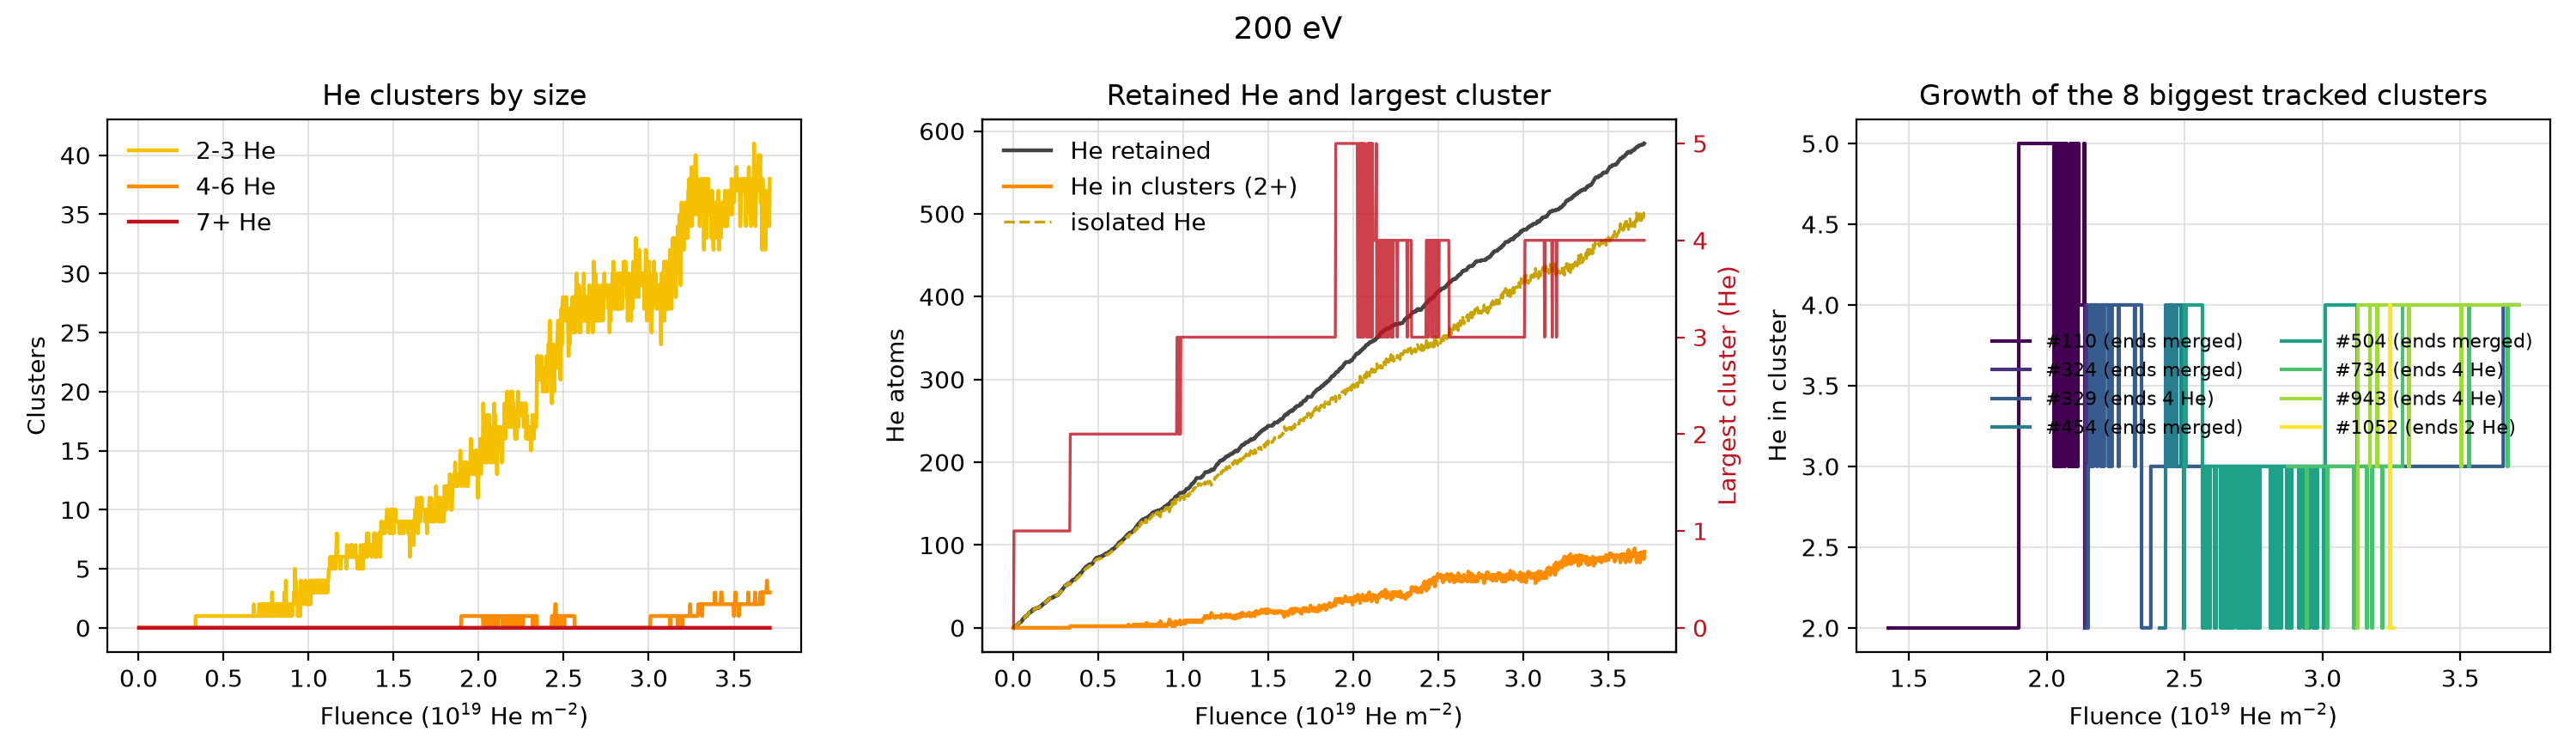

he_depth_profile.png


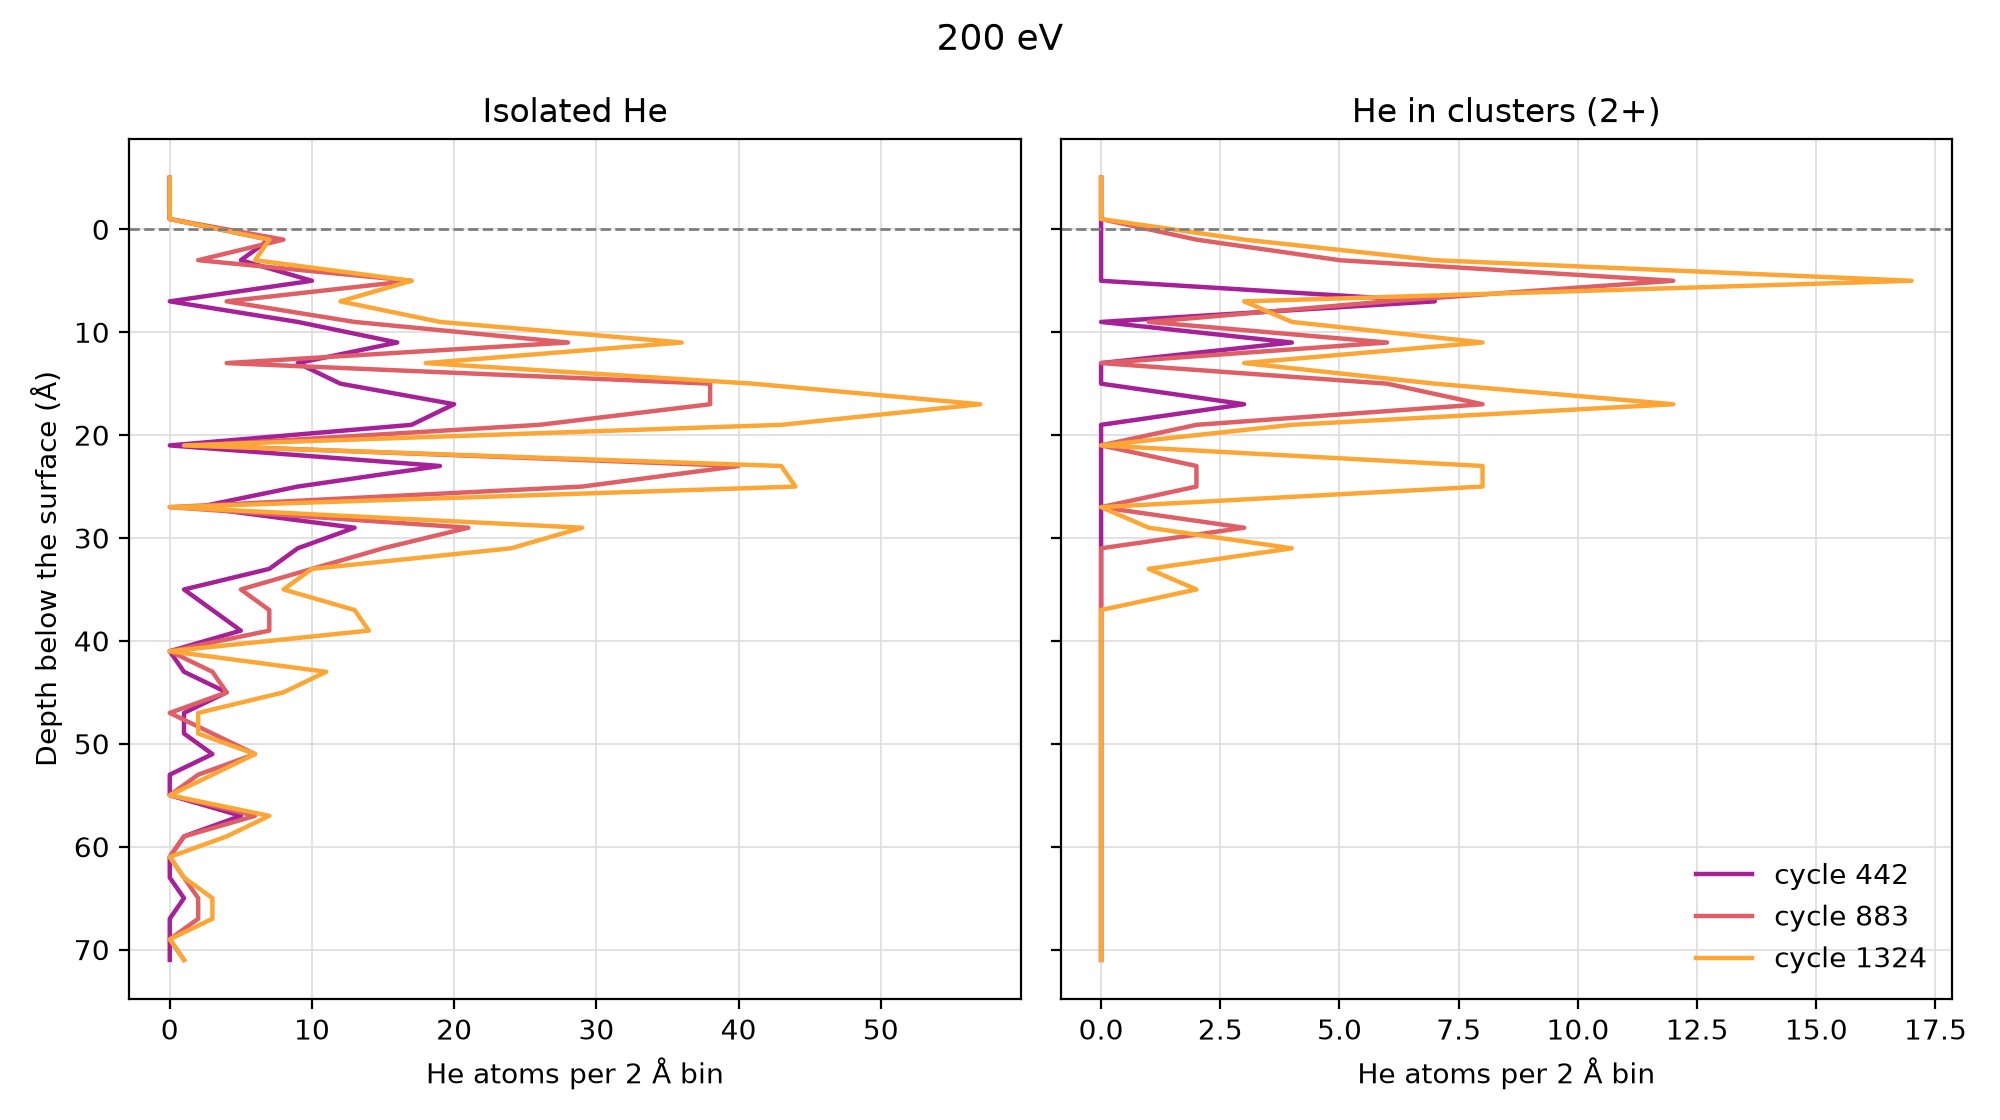

he_clusters_final.png


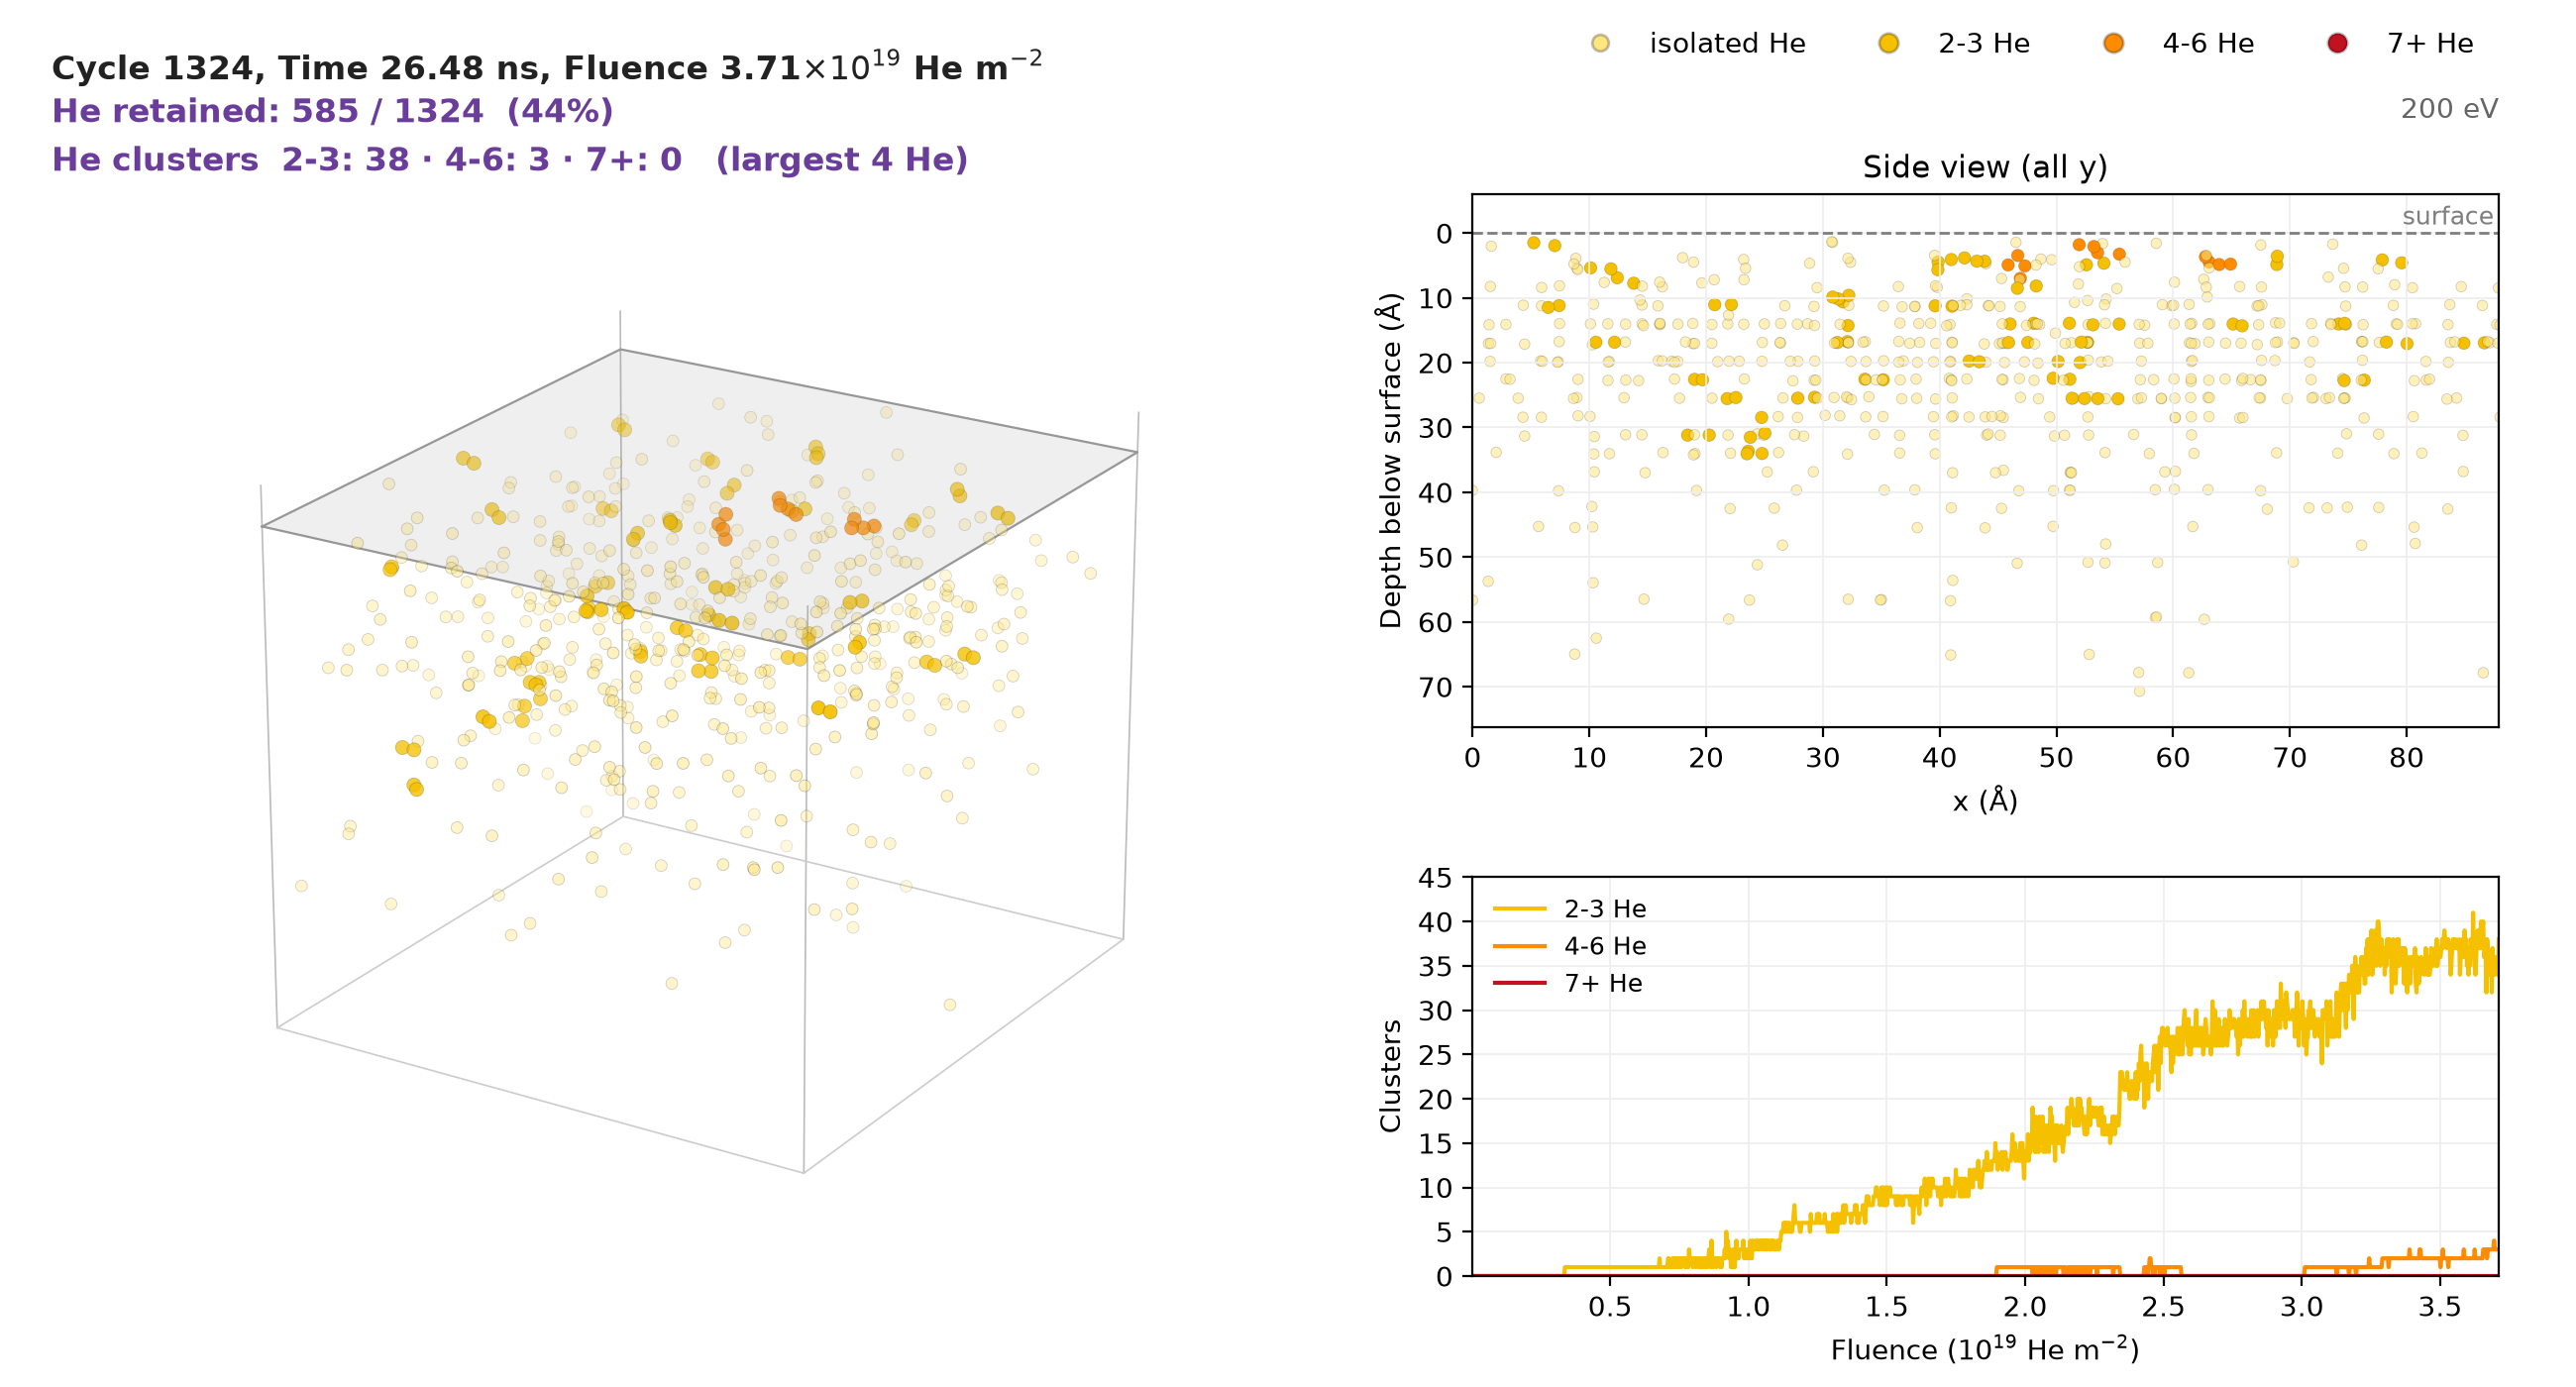

he_clusters.gif


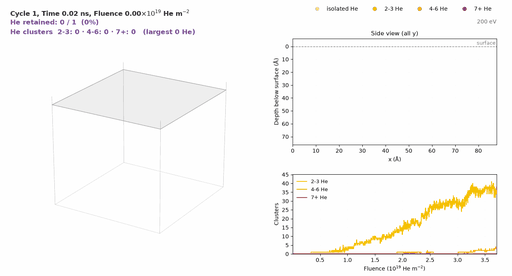

In [3]:
show(os.path.join(NB_RUN, 'he_clusters'), ['he_cluster_evolution.png', 'he_depth_profile.png', 'he_clusters_final.png', 'he_clusters.gif'])